# EDA по классам нектарин, голубика, перец

Задача анализа данных EDA по классам нектарин, голубика, перец заключается в разбиении работы на несколько этапов

- Достать данные, выкачать, посмотреть на разбивку по классам.
- Разбить по классам выбрать нужные, определить фреймворк для разметки
- Проанализировать что за данные, по разрешениям и похожести
- Разметить данные на 3 класса accepted, declined, extra
- Написать код для проверки данных на похожесть по md5 и pHash 
- Сделать анализ данных, написать отчет, подготовить данные для обучения baseline модели

Также в ноутбуке приведен код подготовки данных, в самом ноутбуке практически ничего считать не надо, только отрисовать таблички и графики

## Глосарий
accepted - хорошие данные

declined - данные с гнилью

extra - не данные фруктов и овощей


paper, blueberry, peach - именования классов, которые используются в работе.

## Мета
Для написания кода анализа и прогонки md5, pHash был использован ИИ. Так как этот код является утилитарным и одноразовым.

# Размеченные кадры: норма и гниль

Подгружаем уже посчитанные данные из data. 

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("data")

images = pd.read_csv(DATA / "images.csv")
within = pd.read_csv(DATA / "within.csv")
conflicts = pd.read_csv(DATA / "conflicts.csv")
cosine = pd.read_csv(DATA / "cosine.csv")

print(f"Всего размеченных кадров {len(images)}")

кадров 4774


## Состав и разрешение

In [ ]:
counts = (
    images.groupby(["fruit", "label"])
    .size()
    .rename("images")
    .reset_index()
)
counts

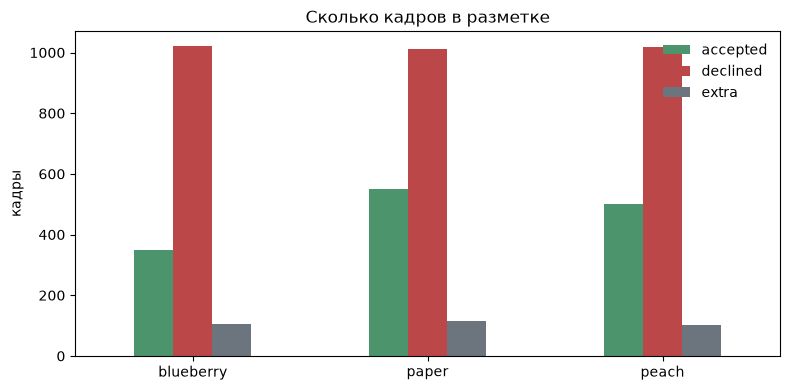

In [3]:
order = ["accepted", "declined", "extra"]
colors = {"accepted": "#4c956c", "declined": "#bc4749", "extra": "#6c757d"}
pivot = counts.pivot(index="fruit", columns="label", values="images")[order]
ax = pivot.plot(kind="bar", color=colors, figsize=(8, 4))
ax.set_xlabel("")
ax.set_ylabel("кадры")
ax.set_title("Сколько кадров в разметке")
ax.tick_params(axis="x", labelrotation=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [4]:
def resolution_bucket(width, height):
    short, long = sorted((int(width), int(height)))
    if short >= 1910 and long >= 2500:
        return "≈1920×2560"
    if short >= 1600:
        return "1600–1919"
    if short >= 800:
        return "800–1599"
    if short >= 400:
        return "400–799"
    return "<400"

bucket_order = ["≈1920×2560", "1600–1919", "800–1599", "400–799", "<400"]
images["resolution"] = [
    resolution_bucket(width, height) for width, height in zip(images["width"], images["height"])
]
resolution = (
    images.groupby(["resolution", "fruit", "label"]).size()
    .unstack(["fruit", "label"], fill_value=0)
    .reindex(bucket_order)
    .reindex(columns=pd.MultiIndex.from_product([["blueberry", "peach", "paper"], order]))
    .fillna(0)
    .astype(int)
)
display(resolution)
resolution.div(resolution.sum(axis=0), axis=1).round(2)

blueberry                   peach                   paper           \
            accepted declined extra accepted declined extra accepted declined   
resolution                                                                      
≈1920×2560       314      709    99      478      895    98      503      697   
1600–1919          2        2     0        4        3     1        0        3   
800–1599           8       65     1       12       27     0       11       99   
400–799           12      180     2        8       81     1       33      176   
<400              13       64     3        0       13     2        3       37   

                  
           extra  
resolution        
≈1920×2560    86  
1600–1919      0  
800–1599       5  
400–799       15  
<400           9

blueberry                   peach                   paper           \
            accepted declined extra accepted declined extra accepted declined   
resolution                                                                      
≈1920×2560      0.90     0.70  0.94     0.95     0.88  0.96     0.91     0.69   
1600–1919       0.01     0.00  0.00     0.01     0.00  0.01     0.00     0.00   
800–1599        0.02     0.06  0.01     0.02     0.03  0.00     0.02     0.10   
400–799         0.03     0.18  0.02     0.02     0.08  0.01     0.06     0.17   
<400            0.04     0.06  0.03     0.00     0.01  0.02     0.01     0.04   

                  
           extra  
resolution        
≈1920×2560  0.75  
1600–1919   0.00  
800–1599    0.04  
400–799     0.13  
<400        0.08

## Дубли внутри одной метки

Сначала сравнение только внутри accepted и только внутри declined, по каждому классу отдельно. md5_copies — сколько файлов совпадают байт в байт с другим файлом той же метки. phash_copies — то же для почти одинаковых кадров, порог Хэмминга 2.

In [5]:
copies = within.sort_values(["fruit", "label"])[
    ["fruit", "label", "images", "md5_images", "phash_images"]
].rename(columns={"md5_images": "md5_copies", "phash_images": "phash_copies"})
copies

,fruit,label,images,md5_copies,phash_copies
0,blueberry,accepted,349,0,2
1,blueberry,declined,1020,20,20
2,blueberry,extra,105,0,0
3,paper,accepted,550,13,13
4,paper,declined,1012,6,6
5,paper,extra,115,0,0
6,peach,accepted,502,0,2
7,peach,declined,1019,2,2
8,peach,extra,102,0,0


## Одни и те же кадры в accepted и declined

Потом сравнение между метками, снова внутри одного класса. Здесь MD5 файла из accepted сверялся с MD5 файлов из declined. Совпадение значит, что один и тот же кадр размечен и как норма, и как гниль. pHash с порогом 2 нашёл те же пары.

In [6]:
both_labels = (
    conflicts.groupby(["fruit", "method"])
    .apply(lambda frame: pd.Series({"pairs": frame["group"].nunique(), "images": len(frame)}), include_groups=False)
    .reset_index()
)
both_labels

,fruit,method,pairs,images
0,blueberry,md5,7,14
1,blueberry,phash,7,14
2,paper,md5,3,6
3,paper,phash,3,6
4,peach,md5,2,4
5,peach,phash,2,4


In [7]:
conflicts[conflicts["method"] == "md5"].sort_values(["fruit", "group", "label"])

,fruit,method,group,label,name
0,blueberry,md5,1,accepted,09e7c42f-33b8-4005-b105-8d3c988507c2-38383807-...
1,blueberry,md5,1,declined,38383807-E73B370E4A1444C790DE6AE4C734DB51-98.jpg
2,blueberry,md5,2,accepted,09fdb0f3-1e9a-4081-918c-3e6d84c34486-Terminalь...
3,blueberry,md5,2,declined,Terminal№2Time.2026.5.15.19.48.2.jpeg
4,blueberry,md5,3,accepted,09fdb0f3-1e9a-4081-918c-3e6d84c34486-Terminalь...
5,blueberry,md5,3,declined,Terminal№2Time.2026.5.15.19.50.39.jpeg
6,blueberry,md5,4,accepted,09fdb0f3-1e9a-4081-918c-3e6d84c34486-Terminalь...
7,blueberry,md5,4,declined,Terminal№2Time.2026.5.15.19.51.18.jpeg
8,blueberry,md5,5,accepted,09fdb0f3-1e9a-4081-918c-3e6d84c34486-Terminalь...
9,blueberry,md5,5,declined,Terminal№2Time.2026.5.15.19.52.35.jpeg


## Похожесть внутри класса

Для каждого кадра посчитали цветовую гистограмму. Картинку уменьшили до 64×64, по красному, зелёному и синему каналу взяли по 16 корзин и склеили в один вектор. Дальше обычный косинус из sklearn: если он близок к единице, набор цветов у двух кадров почти один и тот же. Можем проанализировать дальше классы

У голубики все три кривые лежат друг на друге. Ягода почти всегда тёмно-синяя, и гистограмма это хорошо видит она считает, сколько на кадре синего, а отдельную мягкую ягоду на фоне остальных не выделяет. Поэтому гнилой кадр по цвету так же близок к нормальному, как два нормальных друг к другу.

У нектарина распределение шире и стоит ниже, цвет от кадра к кадру меняется сильнее, чем у голубики, но норма и гниль снова накладываются.

В папке встречаются и зелёные, и красные, и жёлтые плоды, фон тоже разный, поэтому две гистограммы чаще расходятся. Кривая между accepted и declined при этом лежит там же, где кривые внутри каждой метки.

В основном график смещен вправо, потому что слева кучкуются изображения слишком выбивающиесчя, наверное дальний план, или захватили весы и тд. В основном изображения похожи друг на друга и иногад полностью совпадают, что подтверждается md5. Метод использовали чтобы еще раз глянуть на дубликаты и посмотреть можно ли пронаблюдать какие-то зависимости между кадрами с гнилью и без, но они лежат примерно в одной плоскости.

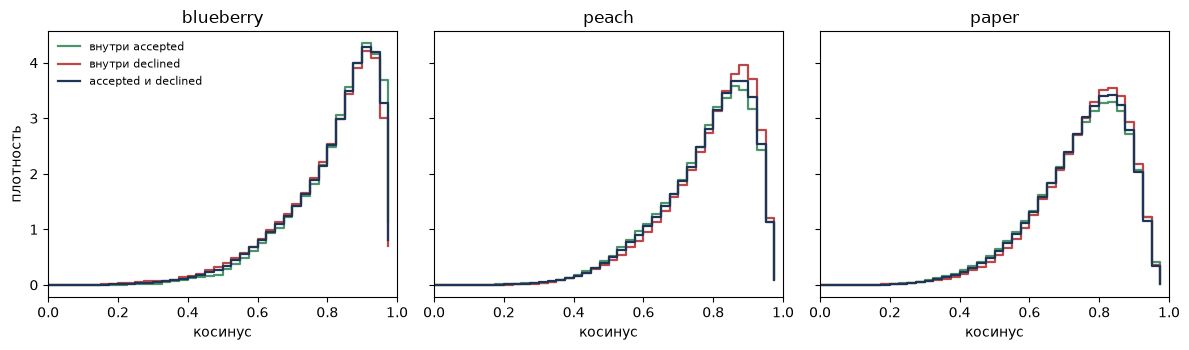

relation,accepted_vs_declined,within_accepted,within_declined
fruit,,,
blueberry,0.850,0.857,0.845
paper,0.772,0.769,0.779
peach,0.809,0.804,0.818


In [8]:
titles = {
    "within_accepted": "внутри accepted",
    "within_declined": "внутри declined",
    "accepted_vs_declined": "accepted и declined",
}
relation_colors = {
    "within_accepted": "#4c956c",
    "within_declined": "#bc4749",
    "accepted_vs_declined": "#1d3557",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, fruit in zip(axes, ["blueberry", "peach", "paper"]):
    part = cosine[cosine["fruit"] == fruit]
    for relation, title in titles.items():
        block = part[part["relation"] == relation]
        ax.step(block["bin"], block["density"], where="post", linewidth=1.6, label=title, color=relation_colors[relation])
    ax.set_title(fruit)
    ax.set_xlabel("косинус")
    ax.set_xlim(0, 1)
axes[0].set_ylabel("плотность")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
(
    cosine.drop_duplicates(["fruit", "relation"])
    .pivot(index="fruit", columns="relation", values="median")
    .round(3)
)

# Выводы

Основной вывод про разметку такой, что есть кадры, которые были на уровне данных запсианы в оба класса. Также после разметки это также произошло. В очтете мы анализировали данны епосле разметки, чтобы сохранить количество данных для анализа, так как предварительная пазметка была сделана до.

Можно сказать, что необходимо дообогатить даныне по голубики, до необходимых 500 не зватает больше сотни изображений. Также данные с гнилью и без очень похожи друг на друга, что мы выяснили по косиносному сходству. Порог косинусу поставить нельзя. Он отрежет часть declined и вместе с ней примерно ту же долю accepted. Цвет кадра гниль от нормы не отделяет, для этого нужен классификатор по самому изображению. 

Для обучения baseline модели необходимо удалить дубликаты из текущих данных и дообогатить голубик хорошими данными.